In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Dropout, Flatten, Dense, Reshape, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.losses import MeanSquaredError
from sklearn.metrics import roc_curve, auc, confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [ ]:
# Normalize the dataset
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, axis=-1)  # Add channel dimension
x_test = np.expand_dims(x_test, axis=-1)
# merge test and training
x_train = np.concatenate((x_train, x_test))
y_train = np.concatenate((y_train, y_test))
del x_test, y_test

In [ ]:
print(x_train.shape, y_train.shape)

(70000, 28, 28, 1) (70000,)


In [ ]:
# Extract normal (background) digits (excluding digit 5)
normal_digits = np.where(y_train != 5)[0]
anomaly_digits = np.where(y_train == 5)[0]
x_normal = x_train[normal_digits]
x_anomalies = x_train[anomaly_digits]

In [ ]:
# Split the normal digits into train, validation, and test sets (50%, 25%, 25%)
x_train_normal, x_temp  = train_test_split(x_normal, test_size=0.5, random_state=42)
x_val_normal, x_test_normal = train_test_split(x_temp, test_size=0.5, random_state=42)

In [ ]:
# Combine validation set with anomalies (label 0 for background, 1 for anomalies)
x_test = np.concatenate([x_test_normal, x_anomalies], axis=0)
y_test = np.concatenate([np.zeros(len(x_test_normal)), np.ones(len(x_anomalies))], axis=0)
# shuffle them if you want. Not really needed

In [ ]:
print(x_train_normal.shape, x_val_normal.shape, x_test_normal.shape)
print(x_test.shape, y_test.shape)

(31843, 28, 28, 1) (15922, 28, 28, 1) (15922, 28, 28, 1)
(22235, 28, 28, 1) (22235,)


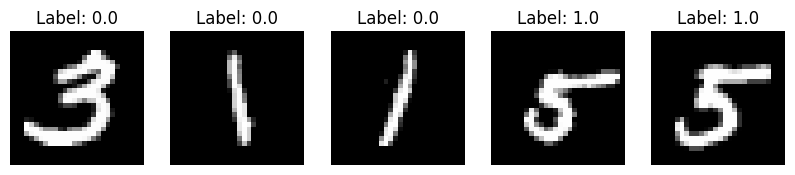

In [ ]:
# Visualize some digits from the dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

In [ ]:
def build_autoencoder(input_shape):
    input_img = Input(shape=input_shape)

    # Encoder
    x = Conv2D(16, (3, 3), padding='same')(input_img)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(8, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(1, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Flatten()(x)
    x = Dense(16,"relu")(x)
    x = Dense(8,"relu")(x)
    x = Dense(16,"relu")(x)
    x = Dense(49,"relu")(x)
    x = Reshape((7,7,1))(x)
    # Decoder
    x = Conv2D(4, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(8, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    autoencoder = Model(input_img, x)
    return autoencoder

In [ ]:
# Build the autoencoder model
input_shape = (28, 28, 1)
autoencoder = build_autoencoder(input_shape)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 1)        │            73 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 1)        │             4 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 49)             │           833 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 4)        │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 4)        │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 7, 7, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 8)      │           29

 Total params: 5,167 (20.18 KB)

 Trainable params: 5,061 (19.77 KB)

 Non-trainable params: 106 (424.00 B)

In [ ]:
# Compile the model
autoencoder.compile(optimizer='adam', loss=MeanSquaredError())

In [ ]:
# Early stopping to avoid overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [ ]:
# Train the autoencoder on the training data
history = autoencoder.fit(x_train_normal, x_train_normal,
                          epochs=20,
                          batch_size=64,
                          shuffle=True,
                          validation_data=(x_val_normal, x_val_normal),
                          callbacks=[early_stopping])

Epoch 1/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - loss: 0.0672 - val_loss: 0.0502
Epoch 2/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0441 - val_loss: 0.0414
Epoch 3/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0396 - val_loss: 0.0381
Epoch 4/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0368 - val_loss: 0.0361
Epoch 5/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0345 - val_loss: 0.0334
Epoch 6/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0332 - val_loss: 0.0326
Epoch 7/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0323 - val_loss: 0.0312
Epoch 8/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0312 - val_loss: 0.0305
Epoch 9/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0304 - val_loss: 0.0305
Epoch 10/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0299 - val_loss: 0.0292
Epoch 11/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0294 - val_loss: 0.0289
Epoch 12/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/st

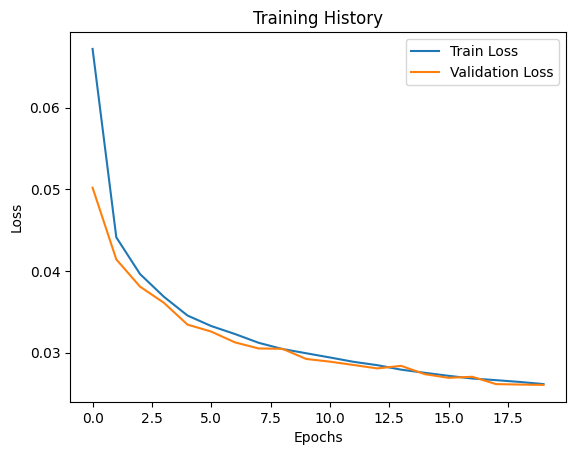

In [ ]:
# Plot the training history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training History')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Calculate MSE for the validation dataset
x_out_test = autoencoder.predict(x_test)
mse_test= np.mean(np.square(x_test - x_out_test), axis=(1, 2, 3)) # Higher MSE indicates a more anomalous image according to this scor

695/695 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


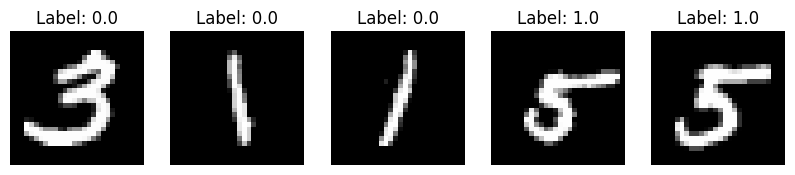

In [ ]:
# Visualize some digits from the dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

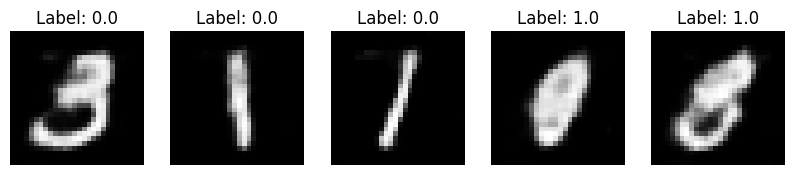

In [ ]:
# Visualize some digits from the dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_out_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

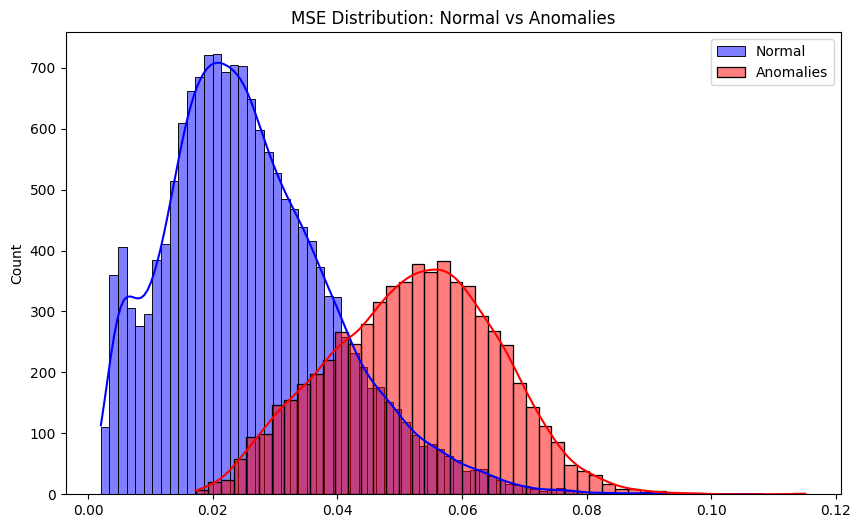

In [ ]:
# Plot the distribution of MSE for normal vs anomalies
plt.figure(figsize=(10,6))
sns.histplot(mse_test[y_test == 0], label='Normal', color='blue', kde=True)
sns.histplot(mse_test[y_test == 1], label='Anomalies', color='red', kde=True)
plt.title('MSE Distribution: Normal vs Anomalies')
plt.legend()
plt.show()

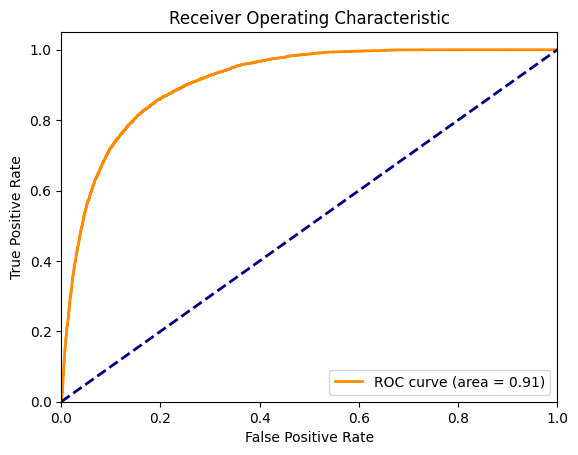

In [ ]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, mse_test)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()